In [34]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal

In [35]:
class quadstate(TypedDict):
    a:int
    b:int
    c:int

    equation:str
    disriciminator:str
    result:str


In [36]:
def show_equation(state:quadstate):
    equation = f'{state["a"]}x^2 {state["b"]:+}x {state["c"]:+}'

    return {"equation":equation}

In [37]:
def calculate_discriminate(state:quadstate):
    discriminator=state["b"]**2-4*state["a"]*state["c"]

    return {"disriciminator":discriminator}

In [38]:
def real_roots(state:quadstate):
    root1=(-state["b"]+state["disriciminator"]**0.5)/2*state["a"]
    root2=(-state["b"]-state["disriciminator"]**0.5)/2*state["a"]

    result=f'The roots are {root1} and {root2}'

    return {"result":result}

In [39]:
def repeated_roots(state:quadstate):
    root=-state["b"]/2*state["a"]
    result=f'The root is {root}'
    return {"result":result}

In [40]:
def no_roots(state:quadstate):
    result=f'No real roots'
    return {"result":result}

In [41]:
def check_condition(state:quadstate)->Literal["real_roots","repeated_roots","no_roots"]:

    if(state["disriciminator"]>0):
        return "real_roots"
    elif(state["disriciminator"]==0):
        return "repeated_roots"
    else:
        return "no_roots"

In [42]:
graph=StateGraph(quadstate)


graph.add_node("show_equation",show_equation)
graph.add_node("calculate_discriminate",calculate_discriminate)

graph.add_node("real_roots",real_roots)
graph.add_node("repeated_roots",repeated_roots)
graph.add_node("no_roots",no_roots)


graph.add_edge(START,"show_equation")
graph.add_edge("show_equation","calculate_discriminate")

graph.add_conditional_edges("calculate_discriminate",check_condition)

graph.add_edge("real_roots",END)
graph.add_edge("repeated_roots",END)
graph.add_edge("no_roots",END)

workflow=graph.compile()

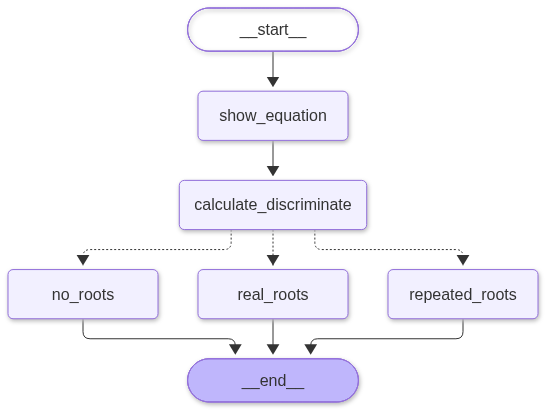

In [43]:
workflow

In [44]:
intial_state={
    "a":4,
    "b":-5,
    "c":2
}

workflow.invoke(intial_state)

{'a': 4,
 'b': -5,
 'c': 2,
 'equation': '4x^2 -5x +2',
 'disriciminator': -7,
 'result': 'No real roots'}